# CS412 Machine Learning | Homework 1

Complete the code and written answers below using CIFAR-10 and scikit-learn's k-NN classifier. Keep the section order and provided function signatures. Use `random_state=42` for data splits and seed 42 for random visualizations.

Run all cells and submit the `.ipynb` file with outputs to SUCourse. No separate report is required. You are expected to be ready to explain your code and results.

In the parts where you are expected to write your answers, keep it concise (about 1-2 paragraphs).

## Imports


In [1]:
%pip install -q datasets
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Dataset and Data Splitting

### 1.1. Load CIFAR-10

CIFAR-10 contains 32 × 32 RGB images from 10 classes. Load the training and test sets and define `class_names` in label order.

In [2]:
# Load CIFAR-10 from HuggingFace (official 50k train / 10k test split)
ds = load_dataset("uoft-cs/cifar10")

# Class names in label order (index 0..9)
class_names = ds["train"].features["label"].names
print("Classes:", class_names)

# Convert PIL images to numpy arrays: shape (N, 32, 32, 3), dtype uint8, values 0-255
X_train_full = np.stack([np.array(img) for img in ds["train"]["img"]]).astype(np.uint8)
y_train_full = np.array(ds["train"]["label"])
X_test_full  = np.stack([np.array(img) for img in ds["test"]["img"]]).astype(np.uint8)
y_test_full  = np.array(ds["test"]["label"])

print("Official train:", X_train_full.shape, y_train_full.shape)
print("Official test: ", X_test_full.shape, y_test_full.shape)

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Official train: (50000, 32, 32, 3) (50000,)
Official test:  (10000, 32, 32, 3) (10000,)


### 1.2. Train, Validation, and Test Sets

Create a dataset containing 6,000 training images, 2,000 validation images, and 2,000 test images. Select training and validation images from the official training set, and test images from the official test set.

Perform all subset selection and data splitting inside this notebook. Use `train_test_split` with `random_state=42`, shuffling, and stratification for every selection and split. Do not use subsets or splits prepared outside the notebook. Print the image and label shapes for all three sets.


In [3]:
# Step 1: select 8,000 images from the official training set (stratified)
X_subset, _, y_subset, _ = train_test_split(
    X_train_full, y_train_full,
    train_size=8000, shuffle=True, stratify=y_train_full, random_state=42
)

# Step 2: split the 8,000 images into 6,000 training and 2,000 validation images
X_train, X_val, y_train, y_val = train_test_split(
    X_subset, y_subset,
    train_size=6000, test_size=2000, shuffle=True, stratify=y_subset, random_state=42
)

# Step 3: select 2,000 images from the official test set (kept aside until final evaluation)
X_test, _, y_test, _ = train_test_split(
    X_test_full, y_test_full,
    train_size=2000, shuffle=True, stratify=y_test_full, random_state=42
)

# Print image and label shapes
print("Train:     ", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:      ", X_test.shape, y_test.shape)

# Print class distributions (number of images per class)
print("\nClass distribution:")
print(f"{'class':<12}{'train':>8}{'val':>8}{'test':>8}")
for i, name in enumerate(class_names):
    print(f"{name:<12}{np.bincount(y_train, minlength=10)[i]:>8}"
          f"{np.bincount(y_val, minlength=10)[i]:>8}"
          f"{np.bincount(y_test, minlength=10)[i]:>8}")

Train:      (6000, 32, 32, 3) (6000,)
Validation: (2000, 32, 32, 3) (2000,)
Test:       (2000, 32, 32, 3) (2000,)

Class distribution:
class          train     val    test
airplane         600     200     200
automobile       600     200     200
bird             600     200     200
cat              600     200     200
deer             600     200     200
dog              600     200     200
frog             600     200     200
horse            600     200     200
ship             600     200     200
truck            600     200     200


## 2. Exploratory Data Analysis

### 2.1. Class Distribution

Using the training set, plot a bar chart of the number of images in each class. Show class names on the x-axis and counts on the y-axis.


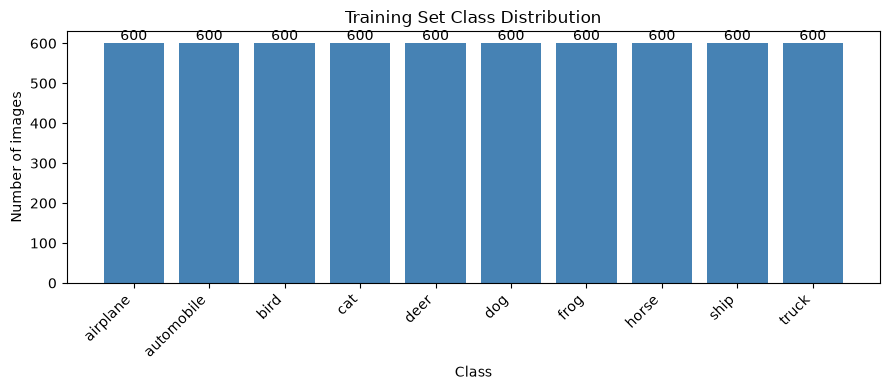

In [4]:
# Count the number of training images per class
train_counts = np.bincount(y_train, minlength=10)

# Bar chart: class names on the x-axis, counts on the y-axis
plt.figure(figsize=(9, 4))
bars = plt.bar(class_names, train_counts, color="steelblue")
plt.bar_label(bars)  # show the exact count on top of each bar
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.title("Training Set Class Distribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 2.2. Pixel Statistics

Using the original training images, print the global pixel mean and standard deviation and the mean pixel intensity for each class. Average over all images, spatial positions, and RGB channels.


Global pixel mean: 120.6744
Global pixel std:  64.2281

Mean pixel intensity per class:
  airplane    141.6324
  automobile  118.3174
  bird        120.0566
  cat         116.3084
  deer        111.5514
  dog         117.4286
  frog        107.1729
  horse       116.2527
  ship        134.8351
  truck       123.1887


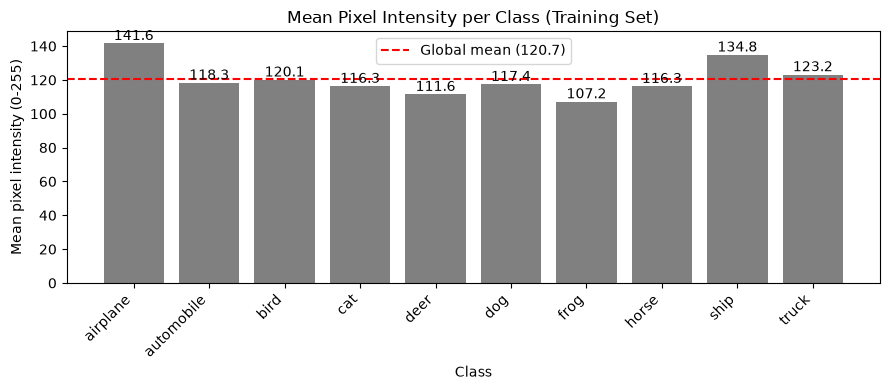

In [5]:
# Use float64 to avoid any overflow / precision issues with uint8
X_train_f = X_train.astype(np.float64)

# Global statistics over all images, spatial positions and RGB channels
global_mean = X_train_f.mean()
global_std = X_train_f.std()
print(f"Global pixel mean: {global_mean:.4f}")
print(f"Global pixel std:  {global_std:.4f}")

# Mean pixel intensity for each class
class_means = np.array([X_train_f[y_train == c].mean() for c in range(10)])
print("\nMean pixel intensity per class:")
for name, m in zip(class_names, class_means):
    print(f"  {name:<12}{m:8.4f}")

# Visual check: per-class mean intensity compared to the global mean
plt.figure(figsize=(9, 4))
bars = plt.bar(class_names, class_means, color="gray")
plt.bar_label(bars, fmt="%.1f")
plt.axhline(global_mean, color="red", linestyle="--", label=f"Global mean ({global_mean:.1f})")
plt.xlabel("Class")
plt.ylabel("Mean pixel intensity (0-255)")
plt.title("Mean Pixel Intensity per Class (Training Set)")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

### 2.3. Image Visualization

Display one training image from each class in a 2 × 5 grid. Label each image with its class name and hide the axes.


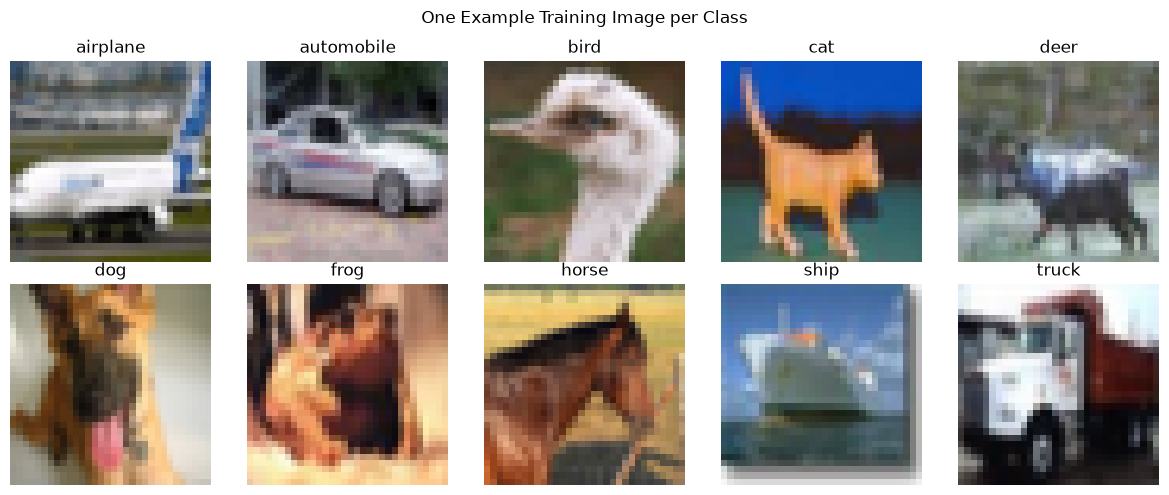

In [6]:
# 2 x 5 grid: one training image per class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for c, ax in enumerate(axes.ravel()):
    idx = np.where(y_train == c)[0][0]  # first training image of class c
    ax.imshow(X_train[idx])
    ax.set_title(class_names[c])
    ax.axis("off")

plt.suptitle("One Example Training Image per Class")
plt.tight_layout()
plt.show()

### 2.4. Comments
Briefly describe what your plots and statistics reveal about the dataset.

The training set is balanced: every class has exactly 600 images, and the validation and test sets have 200 per class. So stratification worked, and accuracy is a fair metric here because no class has more samples than the others.

The global pixel mean is about 120.7 and the standard deviation is about 64.2, so the pixel values are spread over a large part of the 0-255 range. The class means are a bit different from each other. Airplane (141.6) and ship (134.8) are the brightest classes, probably because of the bright sky and water in the background. Frog (107.2) and deer (111.6) are the darkest, probably because of green and brown nature backgrounds. This means that a lot of the difference between classes comes from the background and the overall color, not from the object itself, and k-NN will mostly rely on this since it compares raw pixels. The example images are also very small (32x32) and the objects have different poses, sizes and backgrounds. Some of them, like the frog and the deer, are hard to recognize even for a human. Because of this, I expect classes with similar backgrounds or shapes (like airplane and ship, cat and dog, deer and horse) to be hard for k-NN to separate.

## 3. Preprocessing

### 3.1. Normalization

Complete `normalize_images(images)` to convert pixel values to `float32` and divide by 255. Apply it separately to the training, validation, and test images. Print the training pixel mean and standard deviation before and after normalization. Keep the original images for visualization.


Before normalization: mean = 120.6744, std = 64.2281, range = [0, 255], dtype = uint8
After normalization:  mean = 0.4732, std = 0.2519, range = [0.0, 1.0], dtype = float32


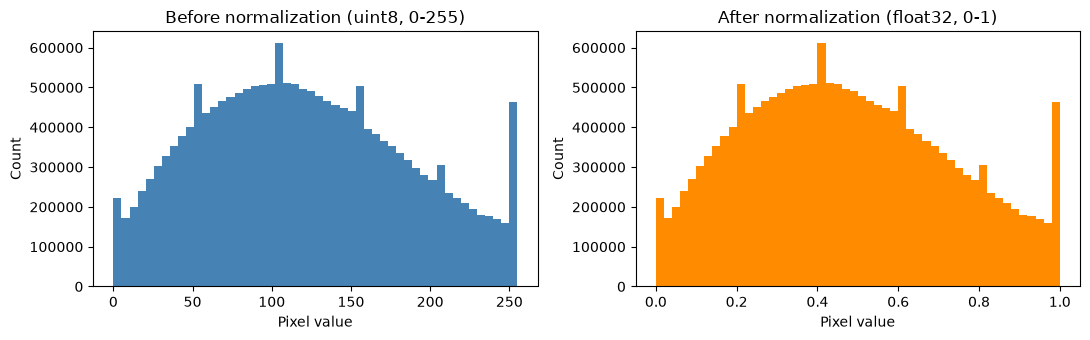

In [7]:
def normalize_images(images):
    # Convert to float32 and scale pixel values from [0, 255] to [0, 1]
    return images.astype(np.float32) / 255.0

# Normalize each split separately (a fixed constant, so no information leaks between splits)
X_train_norm = normalize_images(X_train)
X_val_norm = normalize_images(X_val)
X_test_norm = normalize_images(X_test)

# Training-set statistics before and after normalization
print(f"Before normalization: mean = {X_train.mean(dtype=np.float64):.4f}, "
      f"std = {X_train.std(dtype=np.float64):.4f}, "
      f"range = [{X_train.min()}, {X_train.max()}], dtype = {X_train.dtype}")
print(f"After normalization:  mean = {X_train_norm.mean(dtype=np.float64):.4f}, "
      f"std = {X_train_norm.std(dtype=np.float64):.4f}, "
      f"range = [{X_train_norm.min():.1f}, {X_train_norm.max():.1f}], dtype = {X_train_norm.dtype}")

# Visual check: the distribution shape is unchanged, only the scale of the x-axis changes
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(X_train.ravel(), bins=50, color="steelblue")
axes[0].set_title("Before normalization (uint8, 0-255)")
axes[0].set_xlabel("Pixel value")
axes[0].set_ylabel("Count")
axes[1].hist(X_train_norm.ravel(), bins=50, color="darkorange")
axes[1].set_title("After normalization (float32, 0-1)")
axes[1].set_xlabel("Pixel value")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

### 3.2. Reshaping

Flatten each normalized image into a vector of 3,072 features. Print their shapes.


Train:      (6000, 3072)
Validation: (2000, 3072)
Test:       (2000, 3072)

Reshape is lossless: True


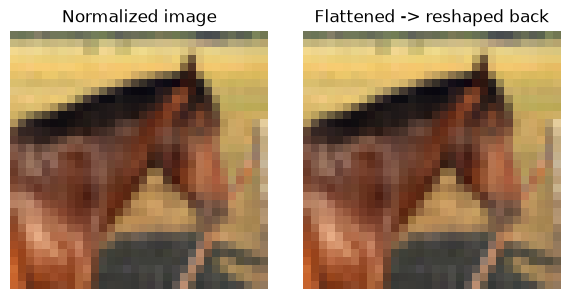

In [8]:
# Flatten each image (32, 32, 3) into a 3,072-dimensional feature vector for scikit-learn
X_train_flat = X_train_norm.reshape(X_train_norm.shape[0], -1)
X_val_flat = X_val_norm.reshape(X_val_norm.shape[0], -1)
X_test_flat = X_test_norm.reshape(X_test_norm.shape[0], -1)

print("Train:     ", X_train_flat.shape)
print("Validation:", X_val_flat.shape)
print("Test:      ", X_test_flat.shape)

# Sanity check: reshaping a flat vector back to (32, 32, 3) recovers the original image exactly
restored = X_train_flat[0].reshape(32, 32, 3)
print("\nReshape is lossless:", np.array_equal(restored, X_train_norm[0]))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X_train_norm[0])
axes[0].set_title("Normalized image")
axes[0].axis("off")
axes[1].imshow(restored)
axes[1].set_title("Flattened -> reshaped back")
axes[1].axis("off")
plt.tight_layout()
plt.show()

### 3.3. Comments
Explain whether this normalization changes nearest-neighbor rankings under Euclidean distance.

No. Normalization divides every pixel value by the same number (255), so the distance between any two images also just gets divided by 255. For example, if image A is closer to the query than image B before normalization, it is still closer after normalization, because both distances shrink by the same factor. The order of the neighbors stays the same, so k-NN finds the same k nearest neighbors and makes the same predictions as it would on the raw 0-255 pixels. The same is true for Manhattan distance, since it is also just a sum of pixel differences that all get divided by 255.

So this normalization does not change the results of k-NN. It mostly makes the numbers easier to work with (floats between 0 and 1). The rankings could change if each pixel was scaled differently, for example with per-feature standardization, because then some pixels would affect the distance more than others.


## 4. k-NN Classification

### 4.1. Hyperparameter Tuning

Complete `evaluate_knn(...)` to fit a `KNeighborsClassifier` on the training data and return its validation accuracy. Use uniform neighbor weights and `algorithm='brute'`.

Evaluate all combinations of `k_values = [1, 3, 5, 7]` and `metric = 'euclidean`. Store the accuracies with one list in the order of `k_values`. Print each result and select `best_k` using validation accuracy only. In a tie, choose the smaller k.


In [9]:
def evaluate_knn(X_train, y_train, X_val, y_val, k, metric):
    # Fit k-NN on the training data and return the validation accuracy
    model = KNeighborsClassifier(n_neighbors=k, weights="uniform",
                                 metric=metric, algorithm="brute")
    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)
    return accuracy_score(y_val, y_val_pred)

k_values = [1, 3, 5, 7]
metrics = 'euclidean'

# Evaluate every k on the validation set (accuracies stored in the order of k_values)
val_accuracies = []
for k in k_values:
    acc = evaluate_knn(X_train_flat, y_train, X_val_flat, y_val, k, metrics)
    val_accuracies.append(acc)

# Results table
print(f"{'k':>3} | {'metric':<10} | {'val accuracy':>12}")
print("-" * 32)
for k, acc in zip(k_values, val_accuracies):
    print(f"{k:>3} | {metrics:<10} | {acc:>12.4f}")

# Select best k using validation accuracy only.
# np.argmax returns the first maximum, and k_values is sorted ascending,
# so in case of a tie the smaller k is chosen.
best_idx = int(np.argmax(val_accuracies))
best_k = k_values[best_idx]
print(f"\nBest k = {best_k} (validation accuracy = {val_accuracies[best_idx]:.4f})")

  k | metric     | val accuracy
--------------------------------
  1 | euclidean  |       0.2635
  3 | euclidean  |       0.2725
  5 | euclidean  |       0.2805
  7 | euclidean  |       0.2880

Best k = 7 (validation accuracy = 0.2880)


Plot validation accuracy against k for the distance metric on the same figure. Label both axes and include a legend.


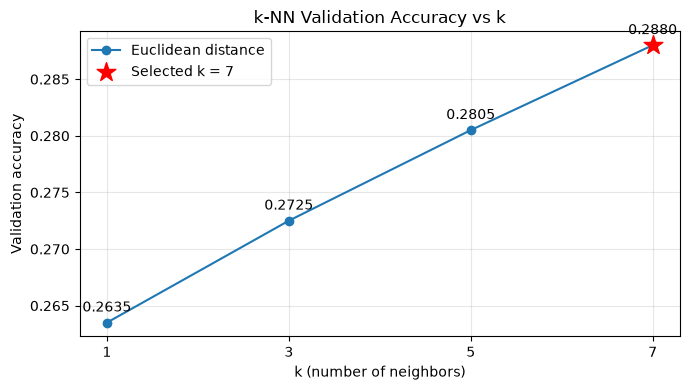

In [10]:
# Validation accuracy as a function of k
plt.figure(figsize=(7, 4))
plt.plot(k_values, val_accuracies, marker="o", label=f"{metrics.capitalize()} distance")

# Write the accuracy value next to each point
for k, acc in zip(k_values, val_accuracies):
    plt.annotate(f"{acc:.4f}", (k, acc), textcoords="offset points",
                 xytext=(0, 8), ha="center")

# Highlight the selected k
plt.scatter([best_k], [val_accuracies[best_idx]], color="red", marker="*",
            s=200, zorder=3, label=f"Selected k = {best_k}")

plt.xlabel("k (number of neighbors)")
plt.ylabel("Validation accuracy")
plt.title("k-NN Validation Accuracy vs k")
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.2. Comments
Briefly discuss how changing k affects the behavior of the classifier. What differences would you
generally expect between small and large values of k?

k controls how many training images vote for the predicted class. With a small k (especially k = 1), the prediction depends on only one or a few neighbors, so a single noisy, mislabeled or accidentally similar image can change the result. The decision boundary becomes very irregular and the model tends to overfit (k = 1 always gets 100% (or 1.0 flat) training accuracy because every training image is its own nearest neighbor, itself). As k increases, the votes of more neighbors are combined, so individual noisy examples matter less and the decision boundary becomes smoother. However, if k becomes too large, neighbors that are far away and not really similar also vote, local details are lost and the model starts to underfit (in the extreme case it would always predict the most common class).

In my results the validation accuracy increased steadily from 0.2635 (k = 1) to 0.2880 (k = 7), so k = 7 was selected. This suggests that raw-pixel distances on CIFAR-10 are quite noisy and averaging over more neighbors helps. Since the accuracy was still increasing at k = 7, an even larger k might work slightly better, but I only compared the given values {1, 3, 5, 7}.

### 4.3. Final Model and Test Evaluation

Combine the flattened training and validation data. Fit a new k-NN model using `best_k`, then predict the test labels. Measure and print the fit and test prediction times separately.

Print test accuracy Plot the confusion matrix with all class names where rows represent true labels and columns represent predicted labels. Store the confusion matrix.


Final training set: (8000, 3072) (8000,)

Fit time:     0.0058 s
Predict time: 0.4869 s

Test accuracy (k = 7): 0.2820
Macro precision: 0.3700
Macro recall:    0.2820
Macro F1:        0.2577


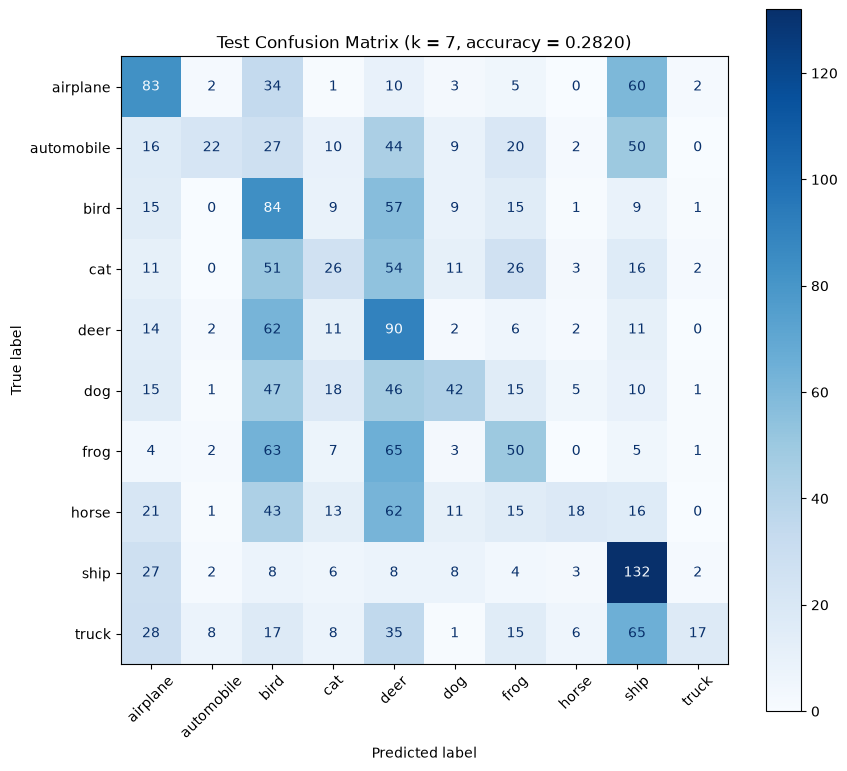

In [11]:
# Combine the preprocessed training and validation splits into the final training set (8,000 images)
X_train_final = np.concatenate([X_train_flat, X_val_flat], axis=0)
y_train_final = np.concatenate([y_train, y_val], axis=0)
print("Final training set:", X_train_final.shape, y_train_final.shape)

# Final model with the selected hyperparameters
final_knn = KNeighborsClassifier(n_neighbors=best_k, weights="uniform",
                                 metric=metrics, algorithm="brute")

# Measure fit time
start = perf_counter()
final_knn.fit(X_train_final, y_train_final)
fit_time = perf_counter() - start

# Measure prediction time on the test set (the test set is used only once, here)
start = perf_counter()
y_test_pred = final_knn.predict(X_test_flat)
predict_time = perf_counter() - start

print(f"\nFit time:     {fit_time:.4f} s")
print(f"Predict time: {predict_time:.4f} s")

# Test metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nTest accuracy (k = {best_k}): {test_accuracy:.4f}")
print(f"Macro precision: {precision_score(y_test, y_test_pred, average='macro'):.4f}")
print(f"Macro recall:    {recall_score(y_test, y_test_pred, average='macro'):.4f}")
print(f"Macro F1:        {f1_score(y_test, y_test_pred, average='macro'):.4f}")

# Confusion matrix (rows = true labels, columns = predicted labels)
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=True)
ax.set_title(f"Test Confusion Matrix (k = {best_k}, accuracy = {test_accuracy:.4f})")
plt.tight_layout()
plt.show()

### 4.3. Comments

The final model (k = 7, trained on 8,000 images) reached a test accuracy of 0.2820, which is very close to the validation accuracy of 0.2880, so the choice of k did not overfit the validation set. This is much better than random guessing (0.10) but still low, which shows the limits of raw-pixel k-NN.

From the diagonal of the confusion matrix, ship is clearly the easiest class (132/200 correct), followed by deer (90), bird (84) and airplane (83). The hardest classes are truck (17/200), horse (18), automobile (22) and cat (26). The columns also show that the model predicts bird, deer and ship far more often than other classes (436, 471 and 374 predictions instead of about 200), while truck, horse and automobile are rarely predicted. Images of these classes often have smooth, uniform backgrounds (sky, water, grass), so they end up close to many other images in pixel space and act as nearest neighbors for images of other classes. This is also why precision (0.37) is higher than recall (0.28): rarely predicted classes like truck have high precision but very low recall.

Fitting took only about 0.006 s while predicting the 2,000 test images took about 0.49 s. Fit() only stores the training data and does not learn any parameters. All the work happens in predict(), where the distance from every test image to all 8,000 training images (each with 3,072 features) has to be computed and sorted. So the prediction cost grows with the size of the training set, which makes k-NN slow at test time for large datasets.

## 5. Error Analysis

### 5.1. Most Confused Class Pairs

Identify the three most confused class pairs using the confusion matrix, combining errors in both directions. Print their class names and confusion counts, and store the results in `top_pairs`.

Three most confused unordered class pairs:
1. bird <-> deer: 119 (bird -> deer: 57, deer -> bird: 62)
2. airplane <-> ship: 87 (airplane -> ship: 60, ship -> airplane: 27)
3. bird <-> frog: 78 (bird -> frog: 15, frog -> bird: 63)


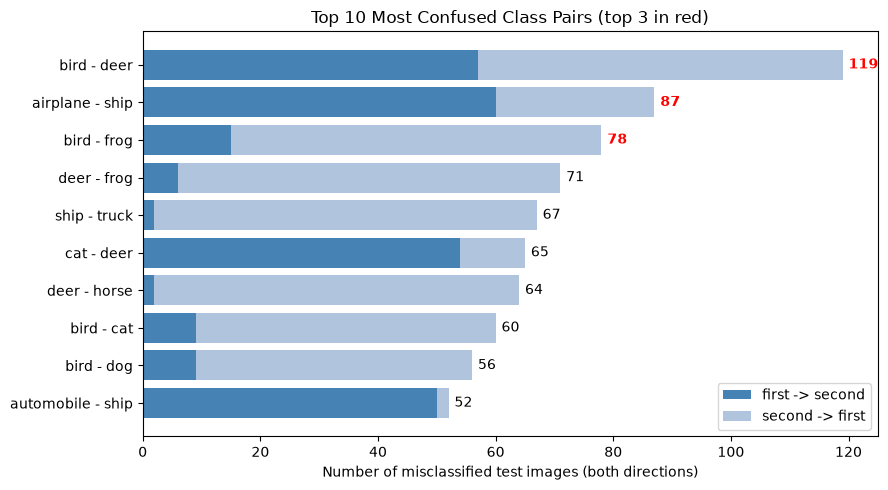

In [12]:
# Combine errors in both directions for each unordered pair (i < j): cm[i, j] + cm[j, i]
pair_counts = []
for i in range(10):
    for j in range(i + 1, 10):
        pair_counts.append((i, j, int(cm[i, j] + cm[j, i])))

# Sort pairs by total confusion (descending); Python's sort is stable, so ties keep a fixed order
pair_counts.sort(key=lambda p: p[2], reverse=True)
top_pairs = pair_counts[:3]

print("Three most confused unordered class pairs:")
for rank, (i, j, total) in enumerate(top_pairs, start=1):
    print(f"{rank}. {class_names[i]} <-> {class_names[j]}: {total} "
          f"({class_names[i]} -> {class_names[j]}: {cm[i, j]}, "
          f"{class_names[j]} -> {class_names[i]}: {cm[j, i]})")

# Visual check: top 10 confused pairs, split by direction, top 3 highlighted
top10 = pair_counts[:10][::-1]  # reversed so the largest bar is on top
labels = [f"{class_names[i]} - {class_names[j]}" for i, j, _ in top10]
a_to_b = [cm[i, j] for i, j, _ in top10]
b_to_a = [cm[j, i] for i, j, _ in top10]

plt.figure(figsize=(9, 5))
plt.barh(labels, a_to_b, color="steelblue", label="first -> second")
plt.barh(labels, b_to_a, left=a_to_b, color="lightsteelblue", label="second -> first")
for y, (_, _, total) in enumerate(top10):
    plt.text(total + 1, y, str(total), va="center",
             color="red" if y >= len(top10) - 3 else "black",
             fontweight="bold" if y >= len(top10) - 3 else "normal")
plt.xlabel("Number of misclassified test images (both directions)")
plt.title("Top 10 Most Confused Class Pairs (top 3 in red)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 5.2. Misclassified Examples

For each pair in `top_pairs`, display five random misclassified test images, or all available examples if fewer than five exist. Label each image with its true and predicted class names. Use seed 42.

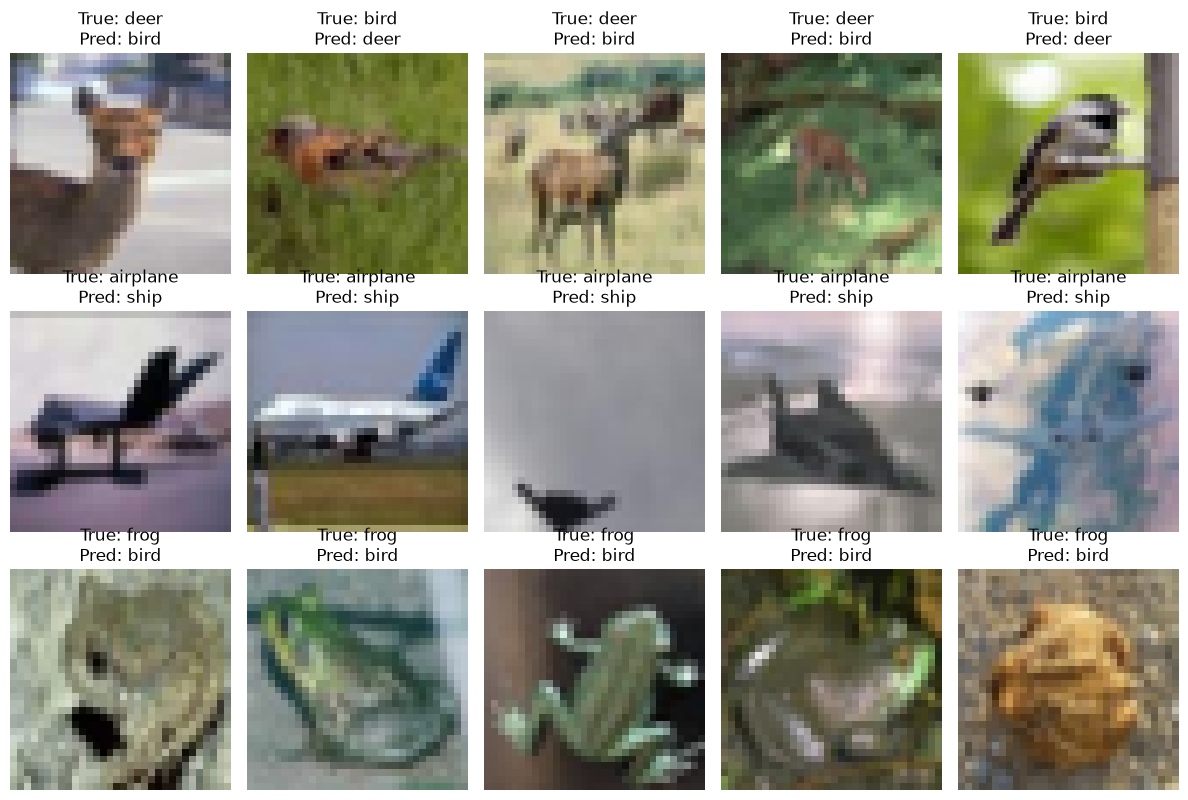

In [13]:
rng = np.random.default_rng(42)  # fixed seed for reproducible sampling

fig, axes = plt.subplots(3, 5, figsize=(12, 8))

for row, (i, j, total) in enumerate(top_pairs):
    # Misclassified test images involving this pair (both directions)
    mask = ((y_test == i) & (y_test_pred == j)) | ((y_test == j) & (y_test_pred == i))
    idx = np.where(mask)[0]
    chosen = rng.choice(idx, size=min(5, len(idx)), replace=False)

    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(chosen):
            t = chosen[col]
            ax.imshow(X_test[t])
            ax.set_title(f"True: {class_names[y_test[t]]}\nPred: {class_names[y_test_pred[t]]}")

plt.tight_layout()
plt.show()

### 5.3 Comments

#### 5.3.1 Q1
Discuss possible reasons for these mistakes based on image appearance and the behavior of
distance-based classifiers.

#### 4.3.2 Q2
Consider the representation used by the classifier. Why might two images that look similar to a
human receive different predictions from k-NN

#### 5.3.1 Q1 Answer

The confused pairs share very similar colors and backgrounds. In the bird-deer examples, both are small brown animals on green or brown natural backgrounds, and the animal covers only a small part of the image. In the airplane-ship examples, a dark object sits on a flat gray, white or blue background, and the sky looks almost the same as water at the pixel level. Some airplanes are so small that the image is mostly plain sky, which looks like a typical ship image. In the frog-bird examples, the frogs are green, gray or brown on textured natural backgrounds, which is also common for bird images. Since k-NN compares images pixel by pixel, the background, which covers most of the pixels, dominates the distance. Images with similar overall colors end up close to each other even if the objects are different. This also explains why bird, deer and ship are predicted so often: their smooth, uniform backgrounds make them close to many other images, so they often appear among the nearest neighbors.

#### 4.3.2 Q2 Answer (5.3.2 ???)

k-NN uses the raw pixel values as a 3,072-dimensional vector, and the Euclidean distance only measures how different the pixel values are at the same positions. It has no idea about shapes, edges or object parts. Two images that look similar to a human can be far apart in this representation, for example if the same object is shifted a few pixels, has a different size, pose or color, is under different lighting, or is in front of a different background. Every pixel changes, so the distance becomes large and the nearest neighbors can come from another class. On the other hand, two different objects with similar colors and backgrounds can be very close. For a better result, features that are robust to shifts and focus on shapes (like the features learned by CNNs), would be needed.

## FOR QUİZ

In [ ]:
import io, requests
from PIL import Image

url = "https://images.unsplash.com/photo-1574071318508-1cdbab80d002?w=32&h=32&fit=crop&fm=png"
img = np.array(Image.open(io.BytesIO(requests.get(url).content)).convert("RGB"))

print("Image shape:", img.shape)

x_flat = normalize_images(img).reshape(1, -1)
print(class_names[final_knn.predict(x_flat)[0]]) 

Image shape: (32, 32, 3)
deer
